In [1]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam

np.random.seed(7)

num_notes = 40
sequence_length = 25
num_sequences = 1200

data = np.random.randint(
    0, num_notes,
    size=(num_sequences, sequence_length)
)

print("Dataset shape:", data.shape)


Dataset shape: (1200, 25)


In [2]:

x_train = data[:, :-1]
y_train = data[:, 1:]

x_train = to_categorical(x_train, num_classes=40)
y_train = to_categorical(y_train, num_classes=40)

print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)


x_train shape: (1200, 24, 40)
y_train shape: (1200, 24, 40)


In [3]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Bidirectional
from tensorflow.keras.layers import Dense, TimeDistributed

model = Sequential([
    Input(shape=(24, 40)),

    Bidirectional(LSTM(100, return_sequences=True)),

    Bidirectional(LSTM(100, return_sequences=True)),

    TimeDistributed(Dense(40, activation='softmax'))
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 24, 200)        │       112,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 24, 200)        │       240,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 24, 40)         │         8,040 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361,640 (1.38 MB)

 Trainable params: 361,640 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2
)


Epoch 1/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.0941 - loss: 3.6586 - val_accuracy: 0.1738 - val_loss: 3.6163
Epoch 2/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.1685 - loss: 3.5351 - val_accuracy: 0.1304 - val_loss: 3.4057
Epoch 3/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.1400 - loss: 3.2674 - val_accuracy: 0.1561 - val_loss: 3.1395
Epoch 4/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.1818 - loss: 2.9702 - val_accuracy: 0.2038 - val_loss: 2.8264
Epoch 5/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.2425 - loss: 2.6224 - val_accuracy: 0.2774 - val_loss: 2.4687
Epoch 6/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.3084 - loss: 2.2602 - val_accuracy: 0.3432 - val_loss: 2.1230
Epoch 7/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.3851 - loss: 1.9150 - val_accuracy: 0.4203 - val_loss: 1.8018
Epoch 8/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.4720 - loss: 1.5932 - val_accuracy: 0.5137 - 

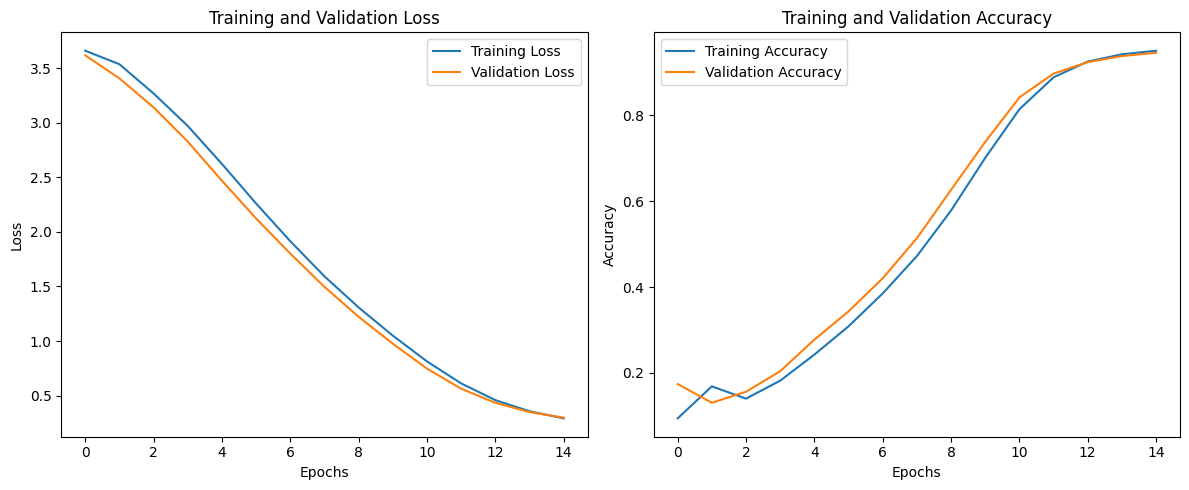

In [7]:

def generate_music(model, start_sequence, num_generated_notes=40):

    current = start_sequence.copy()
    generated = []

    for _ in range(num_generated_notes):

        pred = model.predict(current, verbose=0)

        next_note = np.argmax(pred[:, -1, :], axis=-1)

        generated.append(int(next_note[0]))

        new_note_one_hot = to_categorical(
            next_note,
            num_classes=40
        )[:, np.newaxis, :]

        current = np.concatenate(
            [current[:, 1:, :], new_note_one_hot],
            axis=1
        )

    return generated


# Create random starting sequence
start_sequence = np.random.randint(0, 40, size=(1, 24))

start_sequence = to_categorical(
    start_sequence,
    num_classes=40
)

# Generate 40 notes
generated_notes = generate_music(
    model,
    start_sequence,
    num_generated_notes=40
)

print("Generated notes:", generated_notes)


Generated notes: [22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22]


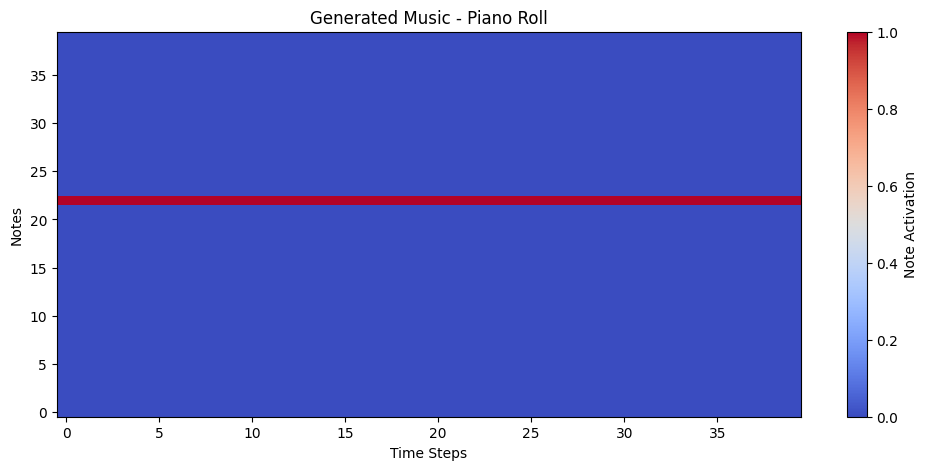

In [8]:

piano_roll = np.zeros((40, 40))

for t, note in enumerate(generated_notes):
    piano_roll[note, t] = 1

plt.figure(figsize=(12, 5))

plt.imshow(
    piano_roll,
    aspect='auto',
    cmap='coolwarm',
    origin='lower'
)

plt.title('Generated Music - Piano Roll')
plt.xlabel('Time Steps')
plt.ylabel('Notes')

plt.colorbar(label='Note Activation')

plt.show()
